# 11 — Evaluasi dan analisis model (Bab 5.5–5.6)

1. **Prediksi dengan Spark:** model terbaik dari notebook 10 dimuat di setiap task Spark (`predict_batch_udf`), lalu memprediksi data validasi dan uji secara paralel. Hasilnya ditulis ke HDFS `/datalake/ml/predictions`.
2. **Evaluasi (5.5)** pada data uji, sekali: precision, recall, F1 per kelas, macro-F1 (metrik utama), weighted-F1, accuracy, dan pembanding "selalu earthquake".
3. **Analisis (5.6):** confusion matrix, skor per jenis sensor, pentingnya fitur konteks, uji posisi, dan contoh prediksi benar/salah.

In [1]:
import sys, os, time
sys.path.insert(0, os.path.abspath('../src'))
from common import *
import cnn, ml_prep as mp
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from pyspark.sql import functions as F
from pyspark.sql.types import ArrayType, FloatType
from pyspark.ml.functions import predict_batch_udf

pd.set_option('display.width', 200, 'display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
spark = spark_session('a2_evaluation')
spark.conf.set('spark.sql.parquet.columnarReaderBatchSize', 512)
spark.conf.set('spark.sql.execution.arrow.maxRecordsPerBatch', 256)
for f in ('ml_prep.py', 'cnn.py'):
    spark.sparkContext.addPyFile(os.path.abspath(f'../src/{f}'))
MODEL = os.path.abspath('../outputs/models/cnn_best.pt')
ck = torch.load(MODEL, weights_only=False)
print(f"model: epoch {ck['epoch']}, macro-F1 validasi {ck['val_macro_f1']:.4f}")

win = spark.read.parquet(f'{HDFS}{ML}/waveforms_z150s')
ctx = spark.read.parquet(f'{HDFS}{ML}/context')
traces = spark.read.parquet(f'{HDFS}{ML}/traces').select('dataset', 'trace_name', 'station_channel_code')

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/11 12:18:33 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/11 12:18:33 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in mesos/standalone/kubernetes and LOCAL_DIRS in YARN).


model: epoch 9, macro-F1 validasi 0.8572


## 1. Prediksi paralel dengan Spark
`predict_batch_udf` memuat model sekali per task, lalu memproses data per batch 256 rekaman. Input = potongan tengah 120 s (detik 15–135) + 9 fitur konteks; keluaran = peluang 4 kelas (softmax). Kelas dengan peluang tertinggi menjadi prediksi.

In [2]:
def predictor(offset=(mp.N - mp.CROP) // 2):
    def make():
        import numpy as np, torch, cnn, ml_prep as mp
        torch.set_num_threads(1)
        state = torch.load(MODEL, weights_only=False)
        model = cnn.CNN(stride1=state['stride1'])
        model.load_state_dict(state['model'])
        model.eval()
        def predict(z, c):
            x = torch.from_numpy(np.ascontiguousarray(z[:, offset:offset + mp.CROP], dtype=np.float32)).unsqueeze(1)
            with torch.no_grad():
                return torch.softmax(model(x, torch.from_numpy(c.astype(np.float32))), 1).numpy()
        return predict
    return predict_batch_udf(make, return_type=ArrayType(FloatType()), batch_size=256,
                             input_tensor_shapes=[[mp.N], [len(mp.CONTEXT_FEATURES)]])

def predict(split, offset=(mp.N - mp.CROP) // 2, context=None):
    c = (context if context is not None else ctx).select('dataset', 'trace_name', F.array(*mp.CONTEXT_FEATURES).alias('c'))
    return (win.filter(F.col('split') == split).select('dataset', 'trace_name', 'label', 'split', 'z')
            .join(c, ['dataset', 'trace_name'])
            .withColumn('p', predictor(offset)('z', 'c'))
            .withColumn('pred', F.element_at(F.array(*[F.lit(c) for c in CLASSES]), F.expr('array_position(p, array_max(p))').cast('int')))
            .drop('z', 'c'))

t0 = time.time()
(predict('val').unionByName(predict('test'))
   .select('dataset', 'trace_name', 'label', 'pred', *[F.col('p')[i].alias(f'p_{c}') for i, c in enumerate(CLASSES)], 'split')
   .write.mode('overwrite').partitionBy('split').parquet(f'{HDFS}{ML}/predictions'))
pred = spark.read.parquet(f'{HDFS}{ML}/predictions')
print(f'selesai dalam {time.time() - t0:.0f} detik')
pred.groupBy('split').count().show()

selesai dalam 255 detik


+-----+-----+
|split|count|
+-----+-----+
| test|35341|
|  val|35078|
+-----+-----+



## 2. Evaluasi pada data uji (Bab 5.5)
Confusion matrix dihitung Spark (`groupBy(label, pred)`); semua metrik diturunkan dari tabel ini.

In [3]:
def confusion(df):
    cm = df.groupBy('label', 'pred').count().toPandas().pivot(index='label', columns='pred', values='count')
    return cm.reindex(index=CLASSES, columns=CLASSES).fillna(0).astype(int)

def metrics(cm):
    m = cm.to_numpy()
    tp = np.diag(m)
    precision = tp / np.maximum(m.sum(0), 1)
    recall = tp / np.maximum(m.sum(1), 1)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    per_class = pd.DataFrame({'precision': precision, 'recall': recall, 'f1': f1, 'support': m.sum(1)}, index=CLASSES)
    summary = {'accuracy': tp.sum() / m.sum(), 'macro_f1': f1.mean(), 'weighted_f1': (f1 * m.sum(1)).sum() / m.sum()}
    return per_class, summary

test = pred.filter("split = 'test'")
cm_test = confusion(test)
per_class, summ = metrics(cm_test)
base_cm = pd.DataFrame(0, index=CLASSES, columns=CLASSES)
base_cm['earthquake'] = cm_test.sum(axis=1)
_, base = metrics(base_cm)
_, summ_val = metrics(confusion(pred.filter("split = 'val'")))

overall = pd.DataFrame({'CNN (uji)': summ, 'CNN (validasi)': summ_val, 'baseline "selalu earthquake" (uji)': base}).T.round(4)
save_md(per_class.round(4).reset_index(names='class'), 'a2_test_metrics_per_class', 'Metrik per kelas pada data uji (35,341 rekaman)')
save_md(overall.reset_index(names='model'), 'a2_test_metrics_overall', 'Metrik keseluruhan: CNN vs baseline')
display(overall)
per_class.round(4)

,accuracy,macro_f1,weighted_f1
CNN (uji),0.9249,0.8609,0.9275
CNN (validasi),0.9233,0.8560,0.9259
"baseline ""selalu earthquake"" (uji)",0.6773,0.2019,0.5470


,precision,recall,f1,support
earthquake,0.9684,0.9314,0.9496,23937
explosion,0.6562,0.9032,0.7601,2407
surface_event,0.7777,0.8233,0.7999,1381
noise,0.9386,0.9295,0.9340,7616


- **Macro-F1 data uji 0.861**, hampir sama dengan validasi (0.856). Data uji tidak pernah dipakai saat memilih model, jadi angka ini tidak terlalu optimis karena pemilihan epoch.
- Dibanding baseline "selalu earthquake": accuracy 0.925 vs 0.677, **macro-F1 0.861 vs 0.202**. Model benar-benar membedakan keempat kelas, bukan hanya menebak kelas mayoritas.
- **Earthquake (F1 0.95) dan noise (0.93)** paling mudah dikenali.
- **Explosion: recall 0.90 tetapi precision 0.66.** Model menemukan 90% ledakan, tetapi sepertiga tebakan "ledakan" sebenarnya kelas lain. Ini konsekuensi bobot kelas (ledakan 3,7×): model lebih memilih alarm palsu daripada melewatkan ledakan.
- **Surface event (F1 0.80)** seimbang: precision 0.78, recall 0.82.

## 3. Confusion matrix
Baris = kelas asli, kolom = kelas tebakan. Kiri: jumlah rekaman. Kanan: % per baris (= recall di diagonal).

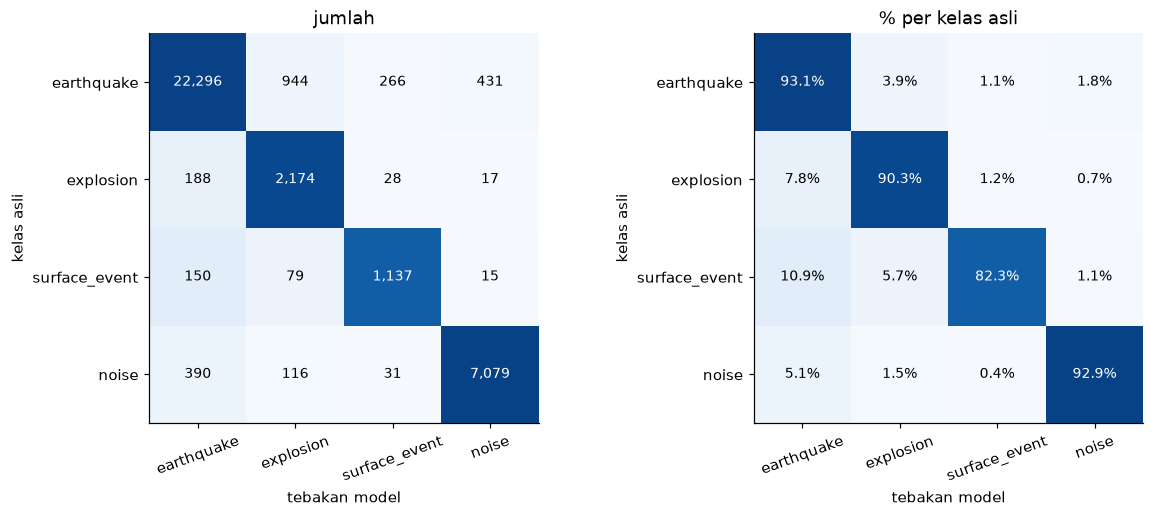

'/Users/axelnakata/Documents/BigData-Earthquake/outputs/tables/a2_confusion_matrix.md'

In [4]:
pct = cm_test.div(cm_test.sum(axis=1), axis=0) * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, data, fmt_, title in [(axes[0], cm_test, '{:,.0f}', 'jumlah'), (axes[1], pct, '{:.1f}%', '% per kelas asli')]:
    ax.imshow(pct.values, cmap='Blues', vmin=0, vmax=100)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, fmt_.format(data.iloc[i, j]), ha='center', va='center', fontsize=9,
                    color='white' if pct.iloc[i, j] > 60 else 'black')
    ax.set_xticks(range(4), CLASSES, rotation=20); ax.set_yticks(range(4), CLASSES)
    ax.set(xlabel='tebakan model', ylabel='kelas asli', title=title)
save_fig('a2_confusion_matrix'); plt.show()
save_md(cm_test.reset_index(names='asli \\ tebakan'), 'a2_confusion_matrix', 'Confusion matrix data uji (baris = asli, kolom = tebakan)')

- **Kesalahan terbanyak: gempa ditebak ledakan (944 rekaman, 3.9% gempa).** Ini 83% dari semua alarm palsu ledakan (944 dari 1,139). Gempa kecil dangkal dan ledakan tambang menghasilkan bentuk gelombang yang mirip, dan bobot kelas ledakan yang tinggi mendorong model ke arah "ledakan".
- **Gempa ↔ noise:** 431 gempa ditebak noise dan 390 noise ditebak gempa. Ini kemungkinan gempa lemah yang sinyalnya tenggelam di latar.
- **Surface event:** 150 ditebak gempa dan 79 ledakan; sebaliknya 266 gempa ditebak surface event.
- Ledakan jarang terlewat: hanya 188 dari 2,407 yang ditebak gempa.

## 4. Skor per jenis sensor

In [5]:
ts = test.join(traces, ['dataset', 'trace_name'])
by_sensor = {}
for s in ['EH', 'BH', 'HH']:
    pc, sm = metrics(confusion(ts.filter(F.col('station_channel_code') == s)))
    by_sensor[s] = {'rekaman': int(pc.support.sum()), 'macro_f1': sm['macro_f1'], 'accuracy': sm['accuracy'], **pc.f1.add_prefix('f1_').to_dict()}
by_sensor = pd.DataFrame(by_sensor).T.round(4)
by_sensor['rekaman'] = by_sensor.rekaman.astype(int)
save_md(by_sensor.reset_index(names='sensor'), 'a2_metrics_by_sensor', 'Skor data uji per jenis sensor')
by_sensor

,rekaman,macro_f1,accuracy,f1_earthquake,f1_explosion,f1_surface_event,f1_noise
EH,19488,0.8787,0.9342,0.9568,0.7773,0.8355,0.9451
BH,10733,0.8080,0.9109,0.9384,0.7301,0.6433,0.9201
HH,5120,0.8290,0.9186,0.9454,0.7639,0.6818,0.9248


- Rekaman **EH paling baik** (macro-F1 0.879), BH 0.808, HH 0.829. Earthquake, explosion, dan noise hampir sama di ketiga sensor.
- Perbedaan terbesar ada di **surface event: EH 0.84 vs BH 0.64 dan HH 0.68**. 79% surface event direkam sensor EH (notebook 07), jadi contoh BH/HH untuk kelas ini sedikit (data uji: 1,090 EH, 238 BH, 53 HH). Model lebih jarang melihat surface event dari sensor broadband.

## 5. Seberapa bergantung model pada fitur konteks? (permutation importance)
Model **tidak dilatih ulang**. Pada data uji, fitur waktu (6 kolom) diacak antar rekaman, sehingga setiap waveform mendapat waktu milik rekaman lain. Hal yang sama dilakukan untuk fitur sensor (3 kolom). Semakin besar turunnya macro-F1, semakin besar model bergantung pada fitur itu.

In [6]:
time_cols, sensor_cols = mp.CONTEXT_FEATURES[:6], mp.CONTEXT_FEATURES[6:]
ctx_test = ctx.filter("split = 'test'").select('dataset', 'trace_name', *mp.CONTEXT_FEATURES).toPandas()

def shuffled(cols, seed=42):
    df = ctx_test.copy()
    df[cols] = df[cols].to_numpy()[np.random.default_rng(seed).permutation(len(df))]
    return spark.createDataFrame(df)

perm = {'asli (tanpa diacak)': summ['macro_f1']}
for name, cols in [('waktu diacak', time_cols), ('sensor diacak', sensor_cols)]:
    _, s = metrics(confusion(predict('test', context=shuffled(cols))))
    perm[name] = s['macro_f1']
perm = pd.DataFrame({'macro_f1_uji': perm})
perm['turun'] = (perm.macro_f1_uji.iloc[0] - perm.macro_f1_uji).round(4)
save_md(perm.round(4).reset_index(names='skenario'), 'a2_context_permutation', 'Permutation importance fitur konteks (data uji)')
perm.round(4)

,macro_f1_uji,turun
asli (tanpa diacak),0.8609,0.0000
waktu diacak,0.7856,0.0753
sensor diacak,0.8197,0.0412


- Mengacak **waktu** menurunkan macro-F1 0.861 → **0.786 (−0.075)**. Mengacak **sensor**: → **0.820 (−0.041)**.
- Model memang memakai informasi konteks, terutama waktu (ledakan terjadi pada jam kerja). Tetapi tanpa informasi waktu yang benar pun macro-F1 masih 0.79, jauh di atas baseline 0.20. **Sebagian besar kemampuan model berasal dari waveform.**

## 6. Uji posisi: apakah model mengenali bentuk, bukan posisi?
Model dievaluasi ulang pada data uji dengan potongan 120 s yang dimulai di detik 0, 15 (standar), dan 30. Posisi kejadian di dalam potongan bergeser ±15 detik.

In [7]:
shift = {}
for start_s in (0, 15, 30):
    if start_s == 15:
        shift[start_s] = summ['macro_f1']
    else:
        _, s = metrics(confusion(predict('test', offset=start_s * 100)))
        shift[start_s] = s['macro_f1']
shift = pd.DataFrame({'potongan': [f'detik {s}–{s + 120}' for s in shift], 'macro_f1_uji': list(shift.values())}).round(4)
save_md(shift, 'a2_position_test', 'Uji posisi: macro-F1 uji dengan potongan berbeda')
shift

,potongan,macro_f1_uji
0,detik 0–120,0.8542
1,detik 15–135,0.8609
2,detik 30–150,0.8603


- Macro-F1 hanya berubah **≤ 0.007** (0.854–0.861) saat potongan digeser 15 detik ke kiri atau kanan.
- Model mengenali **bentuk** sinyal, bukan **posisi** kejadian di dalam potongan. Crop acak saat training dan global average pooling bekerja sesuai rancangan, sehingga fakta "surface event selalu mulai di detik 70" tidak menjadi jalan pintas.

## 7. Contoh prediksi benar dan salah
Untuk setiap kelas: satu rekaman uji yang ditebak benar dengan paling yakin, dan satu yang salah dengan paling yakin.

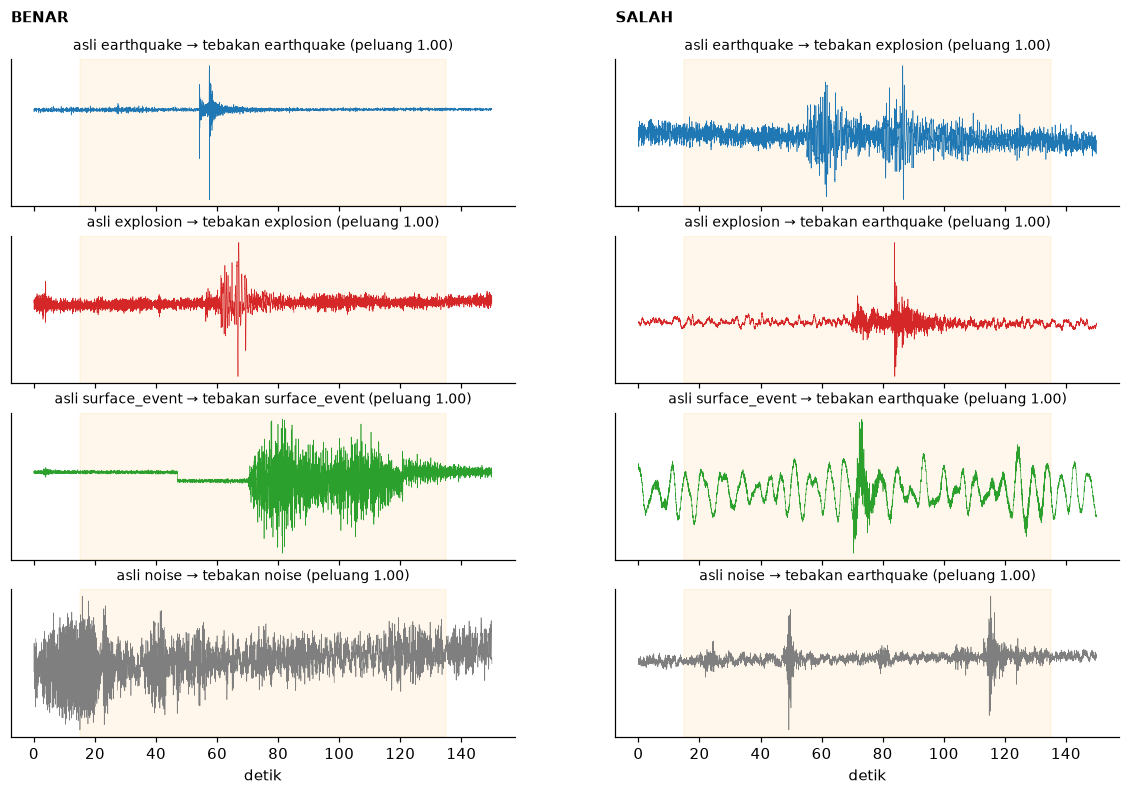

In [8]:
tp = test.toPandas()
tp['conf'] = tp[[f'p_{c}' for c in CLASSES]].max(axis=1)
picks = pd.concat([tp[(tp.label == c) & (tp.pred == c)].nlargest(1, 'conf').assign(kind='benar') for c in CLASSES]
                  + [tp[(tp.label == c) & (tp.pred != c)].nlargest(1, 'conf').assign(kind='salah') for c in CLASSES])
z = (win.filter("split = 'test'").join(F.broadcast(spark.createDataFrame(picks[['dataset', 'trace_name']])), ['dataset', 'trace_name'])
     .select('dataset', 'trace_name', 'z').toPandas())
picks = picks.merge(z, on=['dataset', 'trace_name'])
fig, axes = plt.subplots(4, 2, figsize=(13, 8), sharex=True)
t = np.arange(mp.N) / 100
for i, c in enumerate(CLASSES):
    for j, kind in enumerate(['benar', 'salah']):
        ax, r = axes[i, j], picks[(picks.label == c) & (picks.kind == kind)]
        if r.empty:
            ax.axis('off'); continue
        r = r.iloc[0]
        ax.plot(t, r.z, color=COLORS[c], lw=.4)
        ax.axvspan(15, 135, color='orange', alpha=.08)
        ax.set_title(f'asli {c} → tebakan {r.pred} (peluang {r.conf:.2f})', fontsize=9)
        ax.set_yticks([])
axes[0, 0].text(0, 1.25, 'BENAR', transform=axes[0, 0].transAxes, fontweight='bold')
axes[0, 1].text(0, 1.25, 'SALAH', transform=axes[0, 1].transAxes, fontweight='bold')
axes[-1, 0].set_xlabel('detik'); axes[-1, 1].set_xlabel('detik')
save_fig('a2_prediction_examples'); plt.show()

- **Benar:** contoh dengan keyakinan tertinggi menunjukkan bentuk khas setiap kelas: gempa dengan lonjakan tajam lalu meredam, ledakan dengan paket getaran singkat, surface event dengan getaran panjang yang naik perlahan, dan noise yang bergetar tanpa awal kejadian.
- **Salah:**
  - Rekaman "noise" yang ditebak gempa berisi **dua lonjakan jelas** yang tampak seperti gempa kecil. Kemungkinan ini noise yang mengandung kejadian tak tercatat, yaitu **kesalahan label di data**, bukan kesalahan model.
  - Gempa yang ditebak ledakan direkam dengan latar yang ramai dan beberapa paket getaran.
  - Surface event yang ditebak gempa didominasi gelombang lambat (mikroseismik laut) dengan satu lonjakan pendek.
- Keyakinan 1.00 pada contoh salah menunjukkan bahwa model bisa **sangat yakin tetapi salah**. Peluang softmax tidak boleh dibaca langsung sebagai tingkat kepastian.

## 8. Ringkasan dan keterbatasan
| | Nilai |
|---|---|
| Model | CNN 1D, 200,868 parameter, waveform Z 120 s + 9 fitur konteks |
| Training | Spark TorchDistributor, 5 proses CPU, 12 epoch (berhenti otomatis), 147 menit, model terbaik epoch 9 |
| **Data uji (35,341 rekaman)** | **accuracy 0.925, macro-F1 0.861**, weighted-F1 0.928 |
| Baseline "selalu earthquake" | accuracy 0.677, macro-F1 0.202 |
| F1 per kelas | earthquake 0.95, noise 0.93, surface event 0.80, explosion 0.76 |

**Temuan utama:** (1) kesalahan terbesar adalah gempa ↔ ledakan, kasus yang juga paling sulit bagi analis; (2) model bergantung sebagian pada waktu kejadian, tetapi sebagian besar keputusan datang dari waveform; (3) model tahan terhadap pergeseran posisi kejadian; (4) surface event lebih sulit pada sensor broadband karena contohnya sedikit.

**Keterbatasan:**
- Split acak per rekaman: rekaman stasiun lain dari kejadian yang sama bisa ada di data latih, sehingga skor uji bisa sedikit optimis.
- Hanya komponen Z; gerakan horizontal tidak dipakai.
- Hyperparameter memakai nilai umum tanpa pencarian otomatis.
- Learning rate 0.001 membuat validasi naik-turun (mis. epoch 2).
- Training di CPU satu mesin.

In [9]:
spark.stop()